In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)

In [2]:
from slmsuite.hardware.slms.meadowlark import Meadowlark
from slmsuite.hardware.cameras.alliedvision import AlliedVision
from slmsuite.hardware.cameraslms import FourierSLM

# Paths

SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)

LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)

WAVEFRONT_PHASE_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts"
    r"\YDFC_wavefront_phase_processed_R2p80_50ms_dark.npy"
)



# Initialize hardware ONCE in this notebook


slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)

# cam = AlliedVision(
#     serial="015C2",
#     verbose=True,
# )

# fs = FourierSLM(cam, slm)

cal_file = r"c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts\YDFC_fourier_pre_wavefront_00000.h5"

# loaded = fs.load_calibration(
#     "fourier",
#     file_path=cal_file
# )

# print("Loaded:", loaded)
# print("Current calibrations:", fs.calibrations.keys())

# print("Current calibrations:")
# print(fs.calibrations.keys())


# ------------------------------------------------------------
# Load the measured correction from disk
#
# This only creates a NumPy array called wavefront_phase.
# It does NOT activate the correction.
# ------------------------------------------------------------

wavefront_phase = np.load(WAVEFRONT_PHASE_PATH)

# Activate measured wavefront correction in slmsuite
slm.source["phase"] = wavefront_phase.copy()

print("SLM source keys:", slm.source.keys())
print("Wavefront correction enabled:", slm.phase_correct)
print("Correction shape:", slm.source["phase"].shape)
# ------------------------------------------------------------
# Inspect our starting state
# ------------------------------------------------------------

print("SLM shape:", slm.shape)
# print("Camera shape:", cam.shape)

print("\nLoaded correction:")
print(" shape :", wavefront_phase.shape)
print(" finite:", np.all(np.isfinite(wavefront_phase)))
print(" min   :", wavefront_phase.min())
print(" max   :", wavefront_phase.max())

print("\nCurrent slm.source keys:")
print(slm.source.keys())

print("\nGlobal default slm.phase_correct:")
print(slm.phase_correct)

c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


Validating DPI awareness...success
Constructing Blink SDK...success
Loading LUT file...SLM source keys: dict_keys(['phase'])
Wavefront correction enabled: True
Correction shape: (1200, 1920)
SLM shape: (1200, 1920)

Loaded correction:
 shape : (1200, 1920)
 finite: True
 min   : 0.0
 max   : 6.2831762207757835

Current slm.source keys:
dict_keys(['phase'])

Global default slm.phase_correct:
True


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# USER PARAMETERS
# ============================================================

# --- SLM geometry ---
ny, nx = slm.shape
pixel_mm = 0.008   # 8 um pixel pitch

# --- Beam centre on SLM (from your beam-profile measurement) ---
# Keep these from your previous notebook unless you want to change them
X0_MM = -1.00
Y0_MM =  0.15

# --- Useful illuminated diameter on the SLM ---
# Your beam is ~9.6 mm 1/e^2 diameter.
# Start a bit conservatively.
USEFUL_DIAMETER_MM = 9.6

# --- Central blocked region corresponding to objective hole ---
# Objective hole 6 mm, relay magnification 3x => ~2 mm on SLM.
# Start slightly larger than nominal.
CENTER_BLOCK_DIAMETER_MM = 2.16   # 270 px diameter -> 135 px radius

# --- Dummy array parameters ---
N_SPOTS_X = 10
N_SPOTS_Y = 10

# This is NOT yet calibrated to 5 um in the atom plane.
# It only sets the computational spacing of the dummy array.
ARRAY_SPACING_FOURIER_PX = 18

# Width of each target spot in computational Fourier plane
TARGET_SIGMA_PX = 1.2

# Number of plain GS iterations (not WGS)
GS_ITERS = 50

# --- Carrier for the array ---
CARRIER_PERIOD_PX = 16
CARRIER_DIRECTION = "x"   # "x" or "y"

# --- Dump grating for the blocked central region ---
CENTER_DUMP_PERIOD_PX = 10
CENTER_DUMP_DIRECTION = "y"

# --- Dump grating outside useful mask ---
OUTER_DUMP_PERIOD_PX = -8     # negative sign means opposite direction
OUTER_DUMP_DIRECTION = "x"

# Random seed for repeatability
RNG_SEED = 3

=== Dummy 10x10 hologram with central blocked region ===
SLM shape                    : (1200, 1920)
Beam centre [mm]             : -1.0 0.15
Useful diameter [mm]         : 9.6
Useful radius [px]           : 600.0
Center blocked diameter [mm] : 2.16
Center blocked radius [px]   : 135.0
Array size                   : 10 x 10
Array spacing (Fourier px)   : 18
Carrier                      : 16 px x
Center dump                  : 10 px y
Outer dump                   : -8 px x


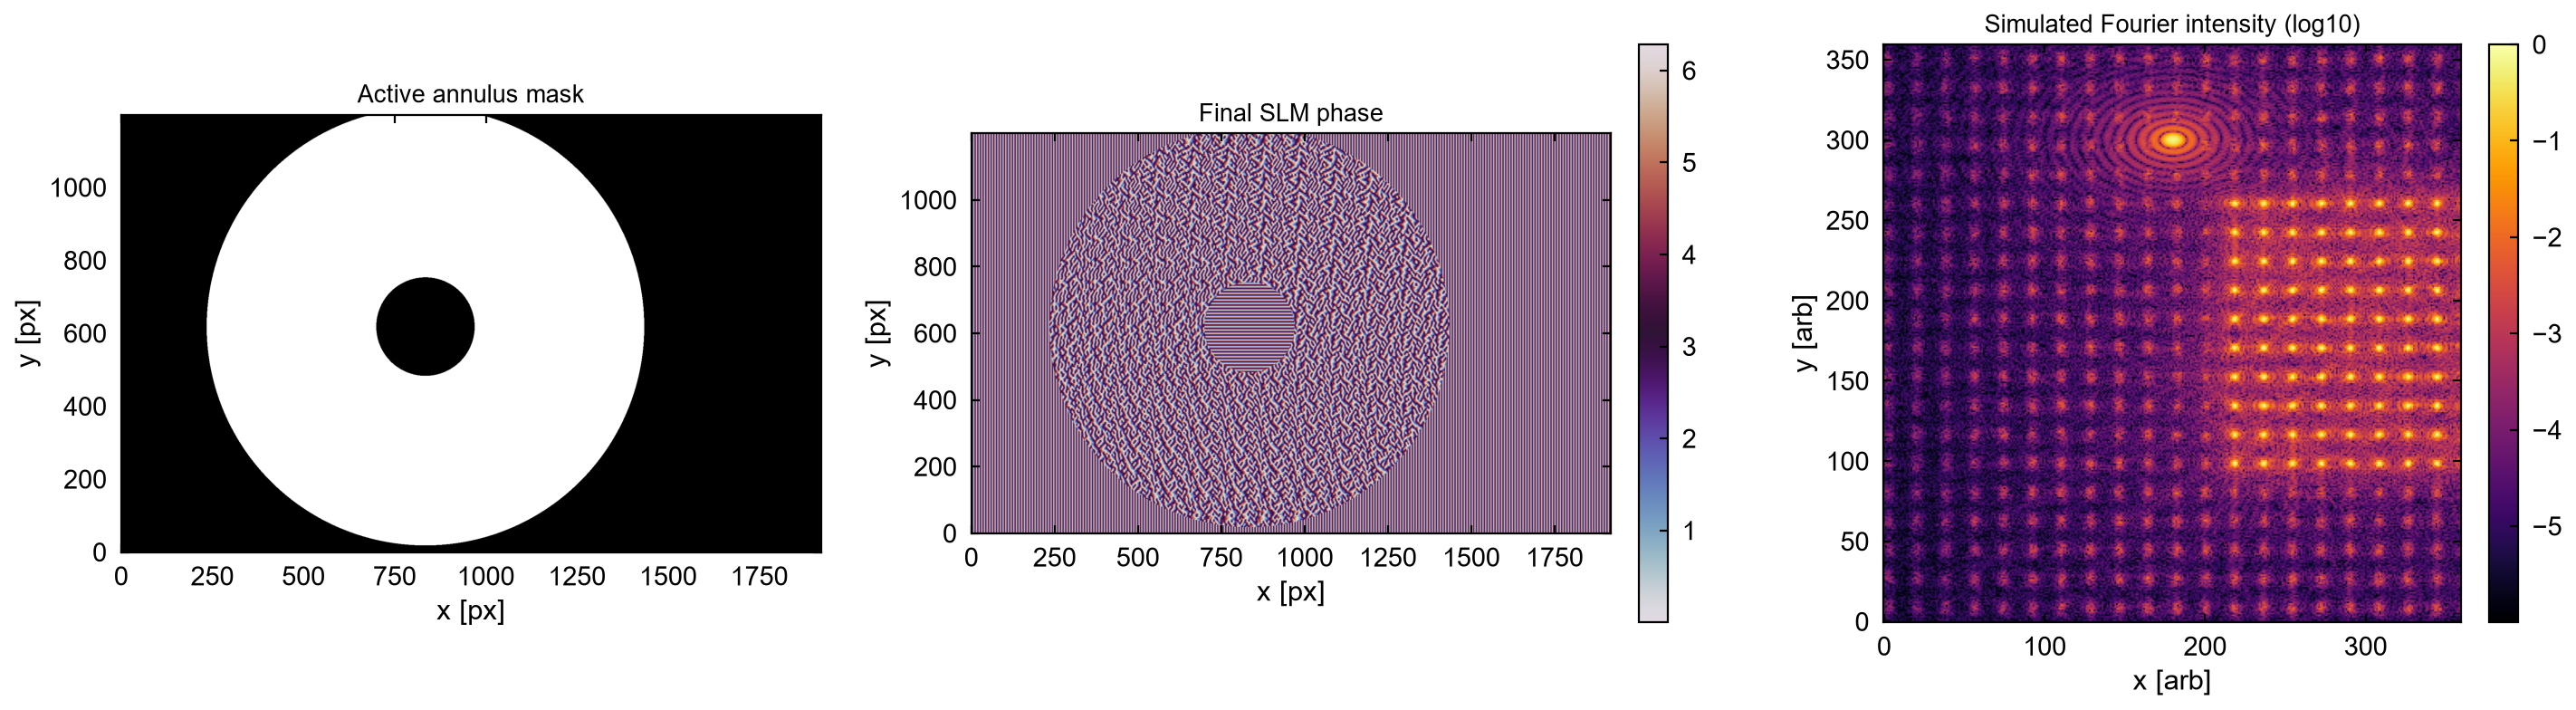

In [4]:
# ============================================================
# COORDINATES
# ============================================================

cx = (nx - 1) / 2
cy = (ny - 1) / 2

yy, xx = np.indices((ny, nx))

x_px = xx - cx
y_px = yy - cy

x_mm = x_px * pixel_mm
y_mm = y_px * pixel_mm

# Coordinates relative to measured beam centre
X = x_mm - X0_MM
Y = y_mm - Y0_MM
R = np.sqrt(X**2 + Y**2)

# ============================================================
# MASKS
# ============================================================

useful_radius_mm = USEFUL_DIAMETER_MM / 2
center_block_radius_mm = CENTER_BLOCK_DIAMETER_MM / 2

mask_center = (R <= center_block_radius_mm)
mask_active = (R > center_block_radius_mm) & (R <= useful_radius_mm)
mask_outer  = (R > useful_radius_mm)

# Amplitude used in the GS loop:
# only the active annulus contributes to the array hologram
pupil_amp = np.zeros((ny, nx), dtype=float)
pupil_amp[mask_active] = 1.0

# ============================================================
# HELPER: blaze
# ============================================================

def make_blaze(period_px, direction):
    if direction == "x":
        coord = x_px
    elif direction == "y":
        coord = y_px
    else:
        raise ValueError("direction must be 'x' or 'y'")

    return 2 * np.pi * coord / period_px

# ============================================================
# TARGET AMPLITUDE IN COMPUTATIONAL FOURIER PLANE
# ============================================================

target_amp = np.zeros((ny, nx), dtype=float)

gx_list = (np.arange(N_SPOTS_X) - (N_SPOTS_X - 1) / 2) * ARRAY_SPACING_FOURIER_PX + cx
gy_list = (np.arange(N_SPOTS_Y) - (N_SPOTS_Y - 1) / 2) * ARRAY_SPACING_FOURIER_PX + cy

for gx in gx_list:
    for gy in gy_list:
        target_amp += np.exp(
            -((xx - gx)**2 + (yy - gy)**2) / (2 * TARGET_SIGMA_PX**2)
        )

target_amp /= target_amp.max()

# ============================================================
# PLAIN GERCHBERG-SAxton (NOT WGS)
# ============================================================

rng = np.random.default_rng(RNG_SEED)

u_slm = pupil_amp * np.exp(1j * 2 * np.pi * rng.random((ny, nx)))

for _ in range(GS_ITERS):
    U = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(u_slm), norm="ortho"))

    # enforce target amplitude in Fourier plane
    U = target_amp * np.exp(1j * np.angle(U))

    u_back = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(U), norm="ortho"))

    # enforce active annulus in SLM plane
    u_slm = pupil_amp * np.exp(1j * np.angle(u_back))

phase_array = np.mod(np.angle(u_slm), 2*np.pi)

# ============================================================
# COMBINE ARRAY + 16 PX CARRIER + DUMP REGIONS
# ============================================================

phase_carrier     = make_blaze(CARRIER_PERIOD_PX,     CARRIER_DIRECTION)
phase_center_dump = make_blaze(CENTER_DUMP_PERIOD_PX, CENTER_DUMP_DIRECTION)
phase_outer_dump  = make_blaze(OUTER_DUMP_PERIOD_PX,  OUTER_DUMP_DIRECTION)

phase_total = np.zeros((ny, nx), dtype=float)

# Active annulus: array hologram + 16-pixel blaze
phase_total[mask_active] = phase_array[mask_active] + phase_carrier[mask_active]

# Central region: do NOT contribute to array, dump elsewhere
phase_total[mask_center] = phase_center_dump[mask_center]

# Outside useful beam: dump elsewhere
phase_total[mask_outer] = phase_outer_dump[mask_outer]

phase_total = np.mod(phase_total, 2*np.pi)

# ============================================================
# OPTIONAL: quick simulated Fourier intensity
# ============================================================

slm_field_for_sim = np.zeros((ny, nx), dtype=complex)

# Give the active annulus unit amplitude
slm_field_for_sim[mask_active] = np.exp(1j * phase_total[mask_active])

# Let the blocked centre also carry light, because in reality that region is illuminated
slm_field_for_sim[mask_center] = np.exp(1j * phase_total[mask_center])

# We ignore the very weak outer region in this simulation
U_sim = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(slm_field_for_sim), norm="ortho"))
I_sim = np.abs(U_sim)**2
I_sim /= I_sim.max()

# ============================================================
# PRINT + PLOT
# ============================================================

center_radius_px = center_block_radius_mm / pixel_mm
useful_radius_px = useful_radius_mm / pixel_mm

print("=== Dummy 10x10 hologram with central blocked region ===")
print("SLM shape                    :", (ny, nx))
print("Beam centre [mm]             :", X0_MM, Y0_MM)
print("Useful diameter [mm]         :", USEFUL_DIAMETER_MM)
print("Useful radius [px]           :", useful_radius_px)
print("Center blocked diameter [mm] :", CENTER_BLOCK_DIAMETER_MM)
print("Center blocked radius [px]   :", center_radius_px)
print("Array size                   :", f"{N_SPOTS_X} x {N_SPOTS_Y}")
print("Array spacing (Fourier px)   :", ARRAY_SPACING_FOURIER_PX)
print("Carrier                      :", CARRIER_PERIOD_PX, "px", CARRIER_DIRECTION)
print("Center dump                  :", CENTER_DUMP_PERIOD_PX, "px", CENTER_DUMP_DIRECTION)
print("Outer dump                   :", OUTER_DUMP_PERIOD_PX, "px", OUTER_DUMP_DIRECTION)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

im0 = ax[0].imshow(mask_active.astype(float), cmap="gray", origin="lower")
ax[0].set_title("Active annulus mask")
ax[0].set_xlabel("x [px]")
ax[0].set_ylabel("y [px]")

im1 = ax[1].imshow(phase_total, cmap="twilight", origin="lower")
ax[1].set_title("Final SLM phase")
ax[1].set_xlabel("x [px]")
ax[1].set_ylabel("y [px]")
plt.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)

# show only central part of simulated Fourier plane
halfwin = 180
cyi, cxi = ny // 2, nx // 2
crop = I_sim[cyi-halfwin:cyi+halfwin, cxi-halfwin:cxi+halfwin]

im2 = ax[2].imshow(np.log10(crop + 1e-6), origin="lower", cmap="inferno")
ax[2].set_title("Simulated Fourier intensity (log10)")
ax[2].set_xlabel("x [arb]")
ax[2].set_ylabel("y [arb]")
plt.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [5]:
# If not already done in this notebook:
# slm.source["phase"] = wavefront_phase.copy()

print("slm.source keys:", slm.source.keys())
print("phase_correct default:", slm.phase_correct)

slm.set_phase(
    phase_total,
    phase_correct=True,   # uses slm.source["phase"] if present
    settle=True,
)

print("Dummy 10x10 annular hologram written to SLM.")

slm.source keys: dict_keys(['phase'])
phase_correct default: True
Dummy 10x10 annular hologram written to SLM.


BARE USABLE SLM PUPIL

Relay:
    L1 = 300.0 mm
    L2 = 1000.0 mm
    M  = 3.333333

Objective central hole:
    objective diameter = 6.000 mm
    SLM diameter       = 1.800 mm
    SLM radius         = 0.900 mm
    SLM radius         = 112.5 pixels

Useful SLM pupil:
    diameter = 9.600 mm
    radius   = 4.800 mm
    radius   = 600.0 pixels

Useful annulus:
    1.800 mm < diameter < 9.600 mm

Phase regions:
    Centre : 4 px y dump
    Active : 16 px x carrier
    Outer  : -4 px y dump


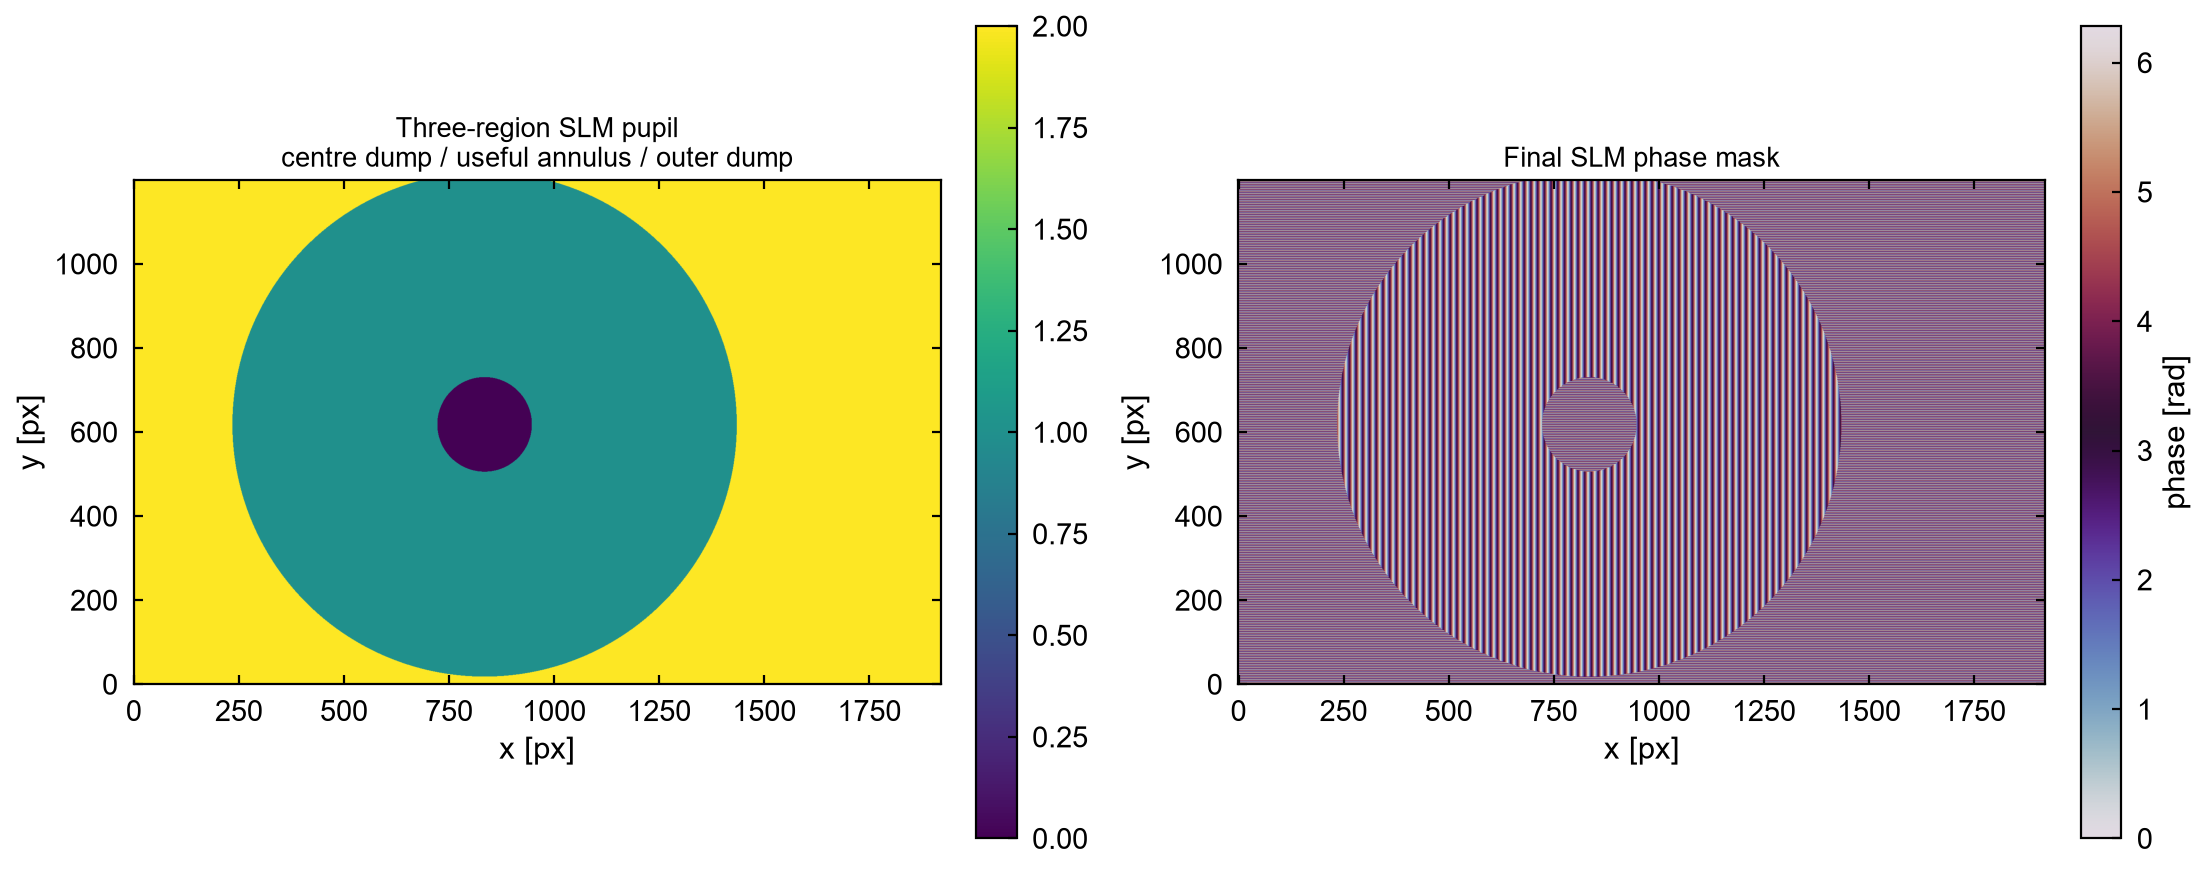

In [6]:
# ============================================================
# BARE USABLE SLM PUPIL
#
# Three concentric regions:
#
#   REGION 1:
#       Corresponds to the 6 mm central hole of the objective.
#       This light is dumped away from the objective.
#
#   REGION 2:
#       Useful annular pupil.
#       ONLY a 16-pixel carrier is applied.
#       No GS / WGS / tweezer hologram.
#
#   REGION 3:
#       Outside the useful 9.6 mm SLM pupil.
#       Dumped in a different direction.
#
#
# Relay:
#
#       L1 = 300 mm
#       L2 = 1000 mm
#
#       M = L2/L1 = 3.3333
#
# Therefore:
#
#       6 mm objective central hole
#                ↓
#       6 / 3.3333 = 1.8 mm diameter on SLM
#
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SLM PARAMETERS
# ============================================================

ny, nx = slm.shape

pixel_mm = 0.008       # 8 um pixel pitch


# ============================================================
# RELAY / OBJECTIVE GEOMETRY
# ============================================================

F1_MM = 300.0
F2_MM = 1000.0

MAGNIFICATION = F2_MM / F1_MM


# Objective central hole
OBJECTIVE_HOLE_DIAMETER_MM = 6.0

# Corresponding diameter at the SLM plane
CENTER_BLOCK_DIAMETER_MM = (
    OBJECTIVE_HOLE_DIAMETER_MM / MAGNIFICATION
)


# Useful illuminated SLM diameter
USEFUL_DIAMETER_MM = 9.6


# ============================================================
# PUPIL CENTRE
# ============================================================
#
# Use the centre corresponding to your actual optical axis /
# beam centre.
#
# These are copied from your previous alignment code.
# Change if you have a better measured value.
# ============================================================

X0_MM = -1.00
Y0_MM =  0.15


# ============================================================
# GRATINGS
# ============================================================
#
# The useful annulus uses the SAME 16-pixel carrier that
# defines your nominal optical axis.
#
# Centre and outer regions are deliberately sent in opposite
# y directions so that they do not overlap each other or the
# useful +x diffraction order.
# ============================================================

CARRIER_PERIOD_PX = 16
CARRIER_DIRECTION = "x"

CENTER_DUMP_PERIOD_PX = 4
CENTER_DUMP_DIRECTION = "y"

OUTER_DUMP_PERIOD_PX = -4
OUTER_DUMP_DIRECTION = "y"


# ============================================================
# SLM COORDINATES
# ============================================================

cx = (nx - 1) / 2
cy = (ny - 1) / 2

yy, xx = np.indices((ny, nx))

x_px = xx - cx
y_px = yy - cy

x_mm = x_px * pixel_mm
y_mm = y_px * pixel_mm


# Coordinates relative to chosen pupil centre
X = x_mm - X0_MM
Y = y_mm - Y0_MM

R = np.sqrt(X**2 + Y**2)


# ============================================================
# DEFINE THREE REGIONS
# ============================================================

center_radius_mm = CENTER_BLOCK_DIAMETER_MM / 2
useful_radius_mm = USEFUL_DIAMETER_MM / 2


# REGION 1:
# Maps onto objective central hole
mask_center = (R <= center_radius_mm)


# REGION 2:
# Light that should actually reach / fill the objective pupil
mask_active = (
    (R > center_radius_mm)
    &
    (R <= useful_radius_mm)
)


# REGION 3:
# Everything outside desired pupil
mask_outer = (R > useful_radius_mm)


# ============================================================
# HELPER FUNCTION: LINEAR BLAZE
# ============================================================

def make_blaze(period_px, direction):

    if direction == "x":
        coord = x_px

    elif direction == "y":
        coord = y_px

    else:
        raise ValueError("direction must be 'x' or 'y'")

    phase = 2 * np.pi * coord / period_px

    return np.mod(phase, 2*np.pi)


# ============================================================
# GENERATE THE THREE PHASE PATTERNS
# ============================================================

# Useful light:
# exact same carrier used for your alignment / tweezers
phase_carrier = make_blaze(
    CARRIER_PERIOD_PX,
    CARRIER_DIRECTION
)


# Central objective-hole dump
phase_center_dump = make_blaze(
    CENTER_DUMP_PERIOD_PX,
    CENTER_DUMP_DIRECTION
)


# Outer unused-light dump
phase_outer_dump = make_blaze(
    OUTER_DUMP_PERIOD_PX,
    OUTER_DUMP_DIRECTION
)


# ============================================================
# COMBINE INTO ONE SLM PHASE MASK
# ============================================================

phase_bare = np.zeros((ny, nx), dtype=float)


# ------------------------------------------------------------
# REGION 1
#
# Light corresponding to central objective hole:
# send away in +y
# ------------------------------------------------------------

phase_bare[mask_center] = (
    phase_center_dump[mask_center]
)


# ------------------------------------------------------------
# REGION 2
#
# Useful annulus:
#
# ONLY the 16-pixel carrier.
#
# This is basically your "one tweezer hahaha" case.
# ------------------------------------------------------------

phase_bare[mask_active] = (
    phase_carrier[mask_active]
)


# ------------------------------------------------------------
# REGION 3
#
# Unused outer SLM:
# send away in -y
# ------------------------------------------------------------

phase_bare[mask_outer] = (
    phase_outer_dump[mask_outer]
)


phase_bare = np.mod(phase_bare, 2*np.pi)


# ============================================================
# INFORMATION
# ============================================================

print("========================================")
print("BARE USABLE SLM PUPIL")
print("========================================")
print()

print("Relay:")
print(f"    L1 = {F1_MM:.1f} mm")
print(f"    L2 = {F2_MM:.1f} mm")
print(f"    M  = {MAGNIFICATION:.6f}")

print()

print("Objective central hole:")
print(
    f"    objective diameter = "
    f"{OBJECTIVE_HOLE_DIAMETER_MM:.3f} mm"
)

print(
    f"    SLM diameter       = "
    f"{CENTER_BLOCK_DIAMETER_MM:.3f} mm"
)

print(
    f"    SLM radius         = "
    f"{center_radius_mm:.3f} mm"
)

print(
    f"    SLM radius         = "
    f"{center_radius_mm/pixel_mm:.1f} pixels"
)

print()

print("Useful SLM pupil:")
print(
    f"    diameter = "
    f"{USEFUL_DIAMETER_MM:.3f} mm"
)

print(
    f"    radius   = "
    f"{useful_radius_mm:.3f} mm"
)

print(
    f"    radius   = "
    f"{useful_radius_mm/pixel_mm:.1f} pixels"
)

print()

print("Useful annulus:")
print(
    f"    {CENTER_BLOCK_DIAMETER_MM:.3f} mm"
    f" < diameter < "
    f"{USEFUL_DIAMETER_MM:.3f} mm"
)

print()

print("Phase regions:")
print(
    f"    Centre : {CENTER_DUMP_PERIOD_PX} px "
    f"{CENTER_DUMP_DIRECTION} dump"
)

print(
    f"    Active : {CARRIER_PERIOD_PX} px "
    f"{CARRIER_DIRECTION} carrier"
)

print(
    f"    Outer  : {OUTER_DUMP_PERIOD_PX} px "
    f"{OUTER_DUMP_DIRECTION} dump"
)


# ============================================================
# PLOT MASKS + FINAL PHASE
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(14, 6))


# Make region image:
#
#   0 = central dump
#   1 = useful pupil
#   2 = outer dump

regions = np.zeros((ny, nx))

regions[mask_center] = 0
regions[mask_active] = 1
regions[mask_outer]  = 2


im0 = ax[0].imshow(
    regions,
    origin="lower",
    cmap="viridis"
)

ax[0].set_title(
    "Three-region SLM pupil\n"
    "centre dump / useful annulus / outer dump"
)

ax[0].set_xlabel("x [px]")
ax[0].set_ylabel("y [px]")

plt.colorbar(
    im0,
    ax=ax[0],
    fraction=0.046,
    pad=0.04
)


im1 = ax[1].imshow(
    phase_bare,
    origin="lower",
    cmap="twilight",
    vmin=0,
    vmax=2*np.pi
)

ax[1].set_title("Final SLM phase mask")

ax[1].set_xlabel("x [px]")
ax[1].set_ylabel("y [px]")

plt.colorbar(
    im1,
    ax=ax[1],
    fraction=0.046,
    pad=0.04,
    label="phase [rad]"
)

plt.tight_layout()
plt.show()

In [7]:
slm.set_phase(
    phase_bare,
    phase_correct=True,
    settle=True,
)

array([[ 17,  17,  17, ...,  46,  46,  46],
       [ 81,  81,  81, ..., 110, 110, 110],
       [145, 145, 145, ..., 174, 174, 174],
       ...,
       [194, 194, 194, ..., 223, 223, 223],
       [  2,   2,   2, ...,  31,  31,  31],
       [ 66,  66,  66, ...,  95,  95,  95]],
      shape=(1200, 1920), dtype=uint8)